In [1]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from pathlib import Path

from src.data.io_utils import read_tif_image, convert_image_to_array

In [2]:
images_brutes = Path("/mnt/x/donnees/images")
masks_brutes = Path("/mnt/x/donnees/masks")


images_patches = Path("/mnt/x/donnees/pachs_64_3classes/images")
masks_patches = Path("/mnt/x/donnees/pachs_64_3classes/masks")

print(f"Dossier images brutes: {images_brutes}")
print(f"Dossier masks brutes: {masks_brutes}")
print(f"Dossier images patches: {images_patches}")
print(f"Dossier masks patches: {masks_patches}")

print(f"\nImages brutes existent: {images_brutes.exists()}")
print(f"Masks brutes existent: {masks_brutes.exists()}")
print(f"Images patches existent: {images_patches.exists()}")
print(f"Masks patches existent: {masks_patches.exists()}")

Dossier images brutes: /mnt/x/donnees/images
Dossier masks brutes: /mnt/x/donnees/masks
Dossier images patches: /mnt/x/donnees/pachs_64_3classes/images
Dossier masks patches: /mnt/x/donnees/pachs_64_3classes/masks

Images brutes existent: True
Masks brutes existent: True
Images patches existent: True
Masks patches existent: True


In [4]:
# Lister les images brutes
image_files = sorted(images_brutes.glob("*.tif"))
mask_files = sorted(masks_brutes.glob("*.tif"))

print(f"Nombre d'images brutes: {len(image_files)}")
print(f"Nombre de masks brutes: {len(mask_files)}")

if len(image_files) > 0:
    print(f"\nPremières images: {[f.name for f in image_files[:5]]}")
    print(f"Dernières images: {[f.name for f in image_files[-5:]]}")

# Lister les patches
image_patch_files = sorted(images_patches.glob("*.tif"))
mask_patch_files = sorted(masks_patches.glob("*.tif"))

print(f"\nNombre de patches images: {len(image_patch_files)}")
print(f"Nombre de patches masks: {len(mask_patch_files)}")

if len(image_patch_files) > 0:
    print(f"Premiers patches: {[f.name for f in image_patch_files[:5]]}")

Nombre d'images brutes: 83
Nombre de masks brutes: 83

Premières images: ['sample_001.tif', 'sample_002.tif', 'sample_003.tif', 'sample_004.tif', 'sample_005.tif']
Dernières images: ['sample_079.tif', 'sample_080.tif', 'sample_081.tif', 'sample_082.tif', 'sample_083.tif']

Nombre de patches images: 19657
Nombre de patches masks: 19657
Premiers patches: ['sample_001000001.tif', 'sample_001000002.tif', 'sample_001000003.tif', 'sample_001000004.tif', 'sample_001000005.tif']


In [5]:
def visualize_3class_mask(mask_array, slice_index, title="Mask 3 Classes", figsize=(10, 8)):
    """
    Visualise un mask 3 classes avec couleurs:
    - Fond (0) = noir
    - Neurones (1) = rouge
    - Vaisseaux/Artefacts (2) = vert/cyan
    """
    mask_slice = mask_array[slice_index, :, :]
    
    # Créer une image RGB
    rgb = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    
    # Classe 0: Fond (noir)
    rgb[mask_slice == 0] = [0, 0, 0]
    
    # Classe 1: Neurones (rouge)
    rgb[mask_slice == 1] = [1, 0, 0]  # Rouge
    
    # Classe 2: Vaisseaux/Artefacts (vert/cyan)
    rgb[mask_slice == 2] = [0, 1, 0]  # Vert
    
    plt.figure(figsize=figsize)
    plt.imshow(rgb)
    plt.title(f"{title} - Slice {slice_index}")
    plt.axis('off')
    
    # Ajouter une légende
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='black', label='Classe 0: Fond'),
        Patch(facecolor='red', label='Classe 1: Neurones'),
        Patch(facecolor='green', label='Classe 2: Vaisseaux/Artefacts')
    ]
    plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
    
    plt.tight_layout()
    plt.show()

In [6]:
def visualize_image_and_mask_3class(image_array, mask_array, slice_index, title="", figsize=(15, 10)):
    """
    Affiche l'image, le mask 3 classes, et la superposition
    """
    # Normaliser l'image pour l'affichage
    img_slice = image_array[slice_index, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    
    mask_slice = mask_array[slice_index, :, :]
    
    # Créer l'overlay avec les 3 classes
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    
    # Classe 1: Neurones (rouge)
    overlay[mask_slice == 1, 0] = 1
    overlay[mask_slice == 1, 1] = 0
    overlay[mask_slice == 1, 2] = 0
    
    # Classe 2: Vaisseaux/Artefacts (vert)
    overlay[mask_slice == 2, 0] = 0
    overlay[mask_slice == 2, 1] = 1
    overlay[mask_slice == 2, 2] = 0
    
    fig, axes = plt.subplots(1, 3, figsize=figsize)
    
    # Image
    axes[0].imshow(img_slice, cmap='gray')
    axes[0].set_title(f"Image - Slice {slice_index}")
    axes[0].axis('off')
    
    # Mask 3 classes
    # Créer une image RGB du mask
    rgb_mask = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    rgb_mask[mask_slice == 0] = [0, 0, 0]
    rgb_mask[mask_slice == 1] = [1, 0, 0]
    rgb_mask[mask_slice == 2] = [0, 1, 0]
    
    axes[1].imshow(rgb_mask)
    axes[1].set_title(f"Mask 3 Classes - Slice {slice_index}")
    axes[1].axis('off')
    
    # Superposition
    axes[2].imshow(overlay)
    axes[2].set_title(f"Superposition\n(Neurones: Rouge, Vaisseaux: Vert)")
    axes[2].axis('off')
    
    # Ajouter une légende
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='black', label='Classe 0: Fond'),
        Patch(facecolor='red', label='Classe 1: Neurones'),
        Patch(facecolor='green', label='Classe 2: Vaisseaux/Artefacts')
    ]
    axes[2].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
    
    if title:
        plt.suptitle(title, fontsize=14)
    
    plt.tight_layout()
    plt.show()
    
    # Afficher les statistiques
    print(f"Statistiques de l'échantillon - Slice {slice_index}:")
    print(f"  Voxels fond (0): {(mask_slice == 0).sum()}")
    print(f"  Voxels neurones (1): {(mask_slice == 1).sum()}")
    print(f"  Voxels vaisseaux (2): {(mask_slice == 2).sum()}")

In [7]:
image_name = "sample_038.tif"
image_path = images_brutes / image_name
mask_path = masks_brutes / image_name

print(f"Recherche de l'image: {image_name}")
print(f"Image existe: {image_path.exists()}")
print(f"Mask existe: {mask_path.exists()}")

Recherche de l'image: sample_038.tif
Image existe: True
Mask existe: True


In [8]:
if image_path.exists() and mask_path.exists():
    print("✅ Chargement de sample_038.tif")
    
    image_sitk = read_tif_image(str(image_path))
    mask_sitk = read_tif_image(str(mask_path))
    
    image_array = convert_image_to_array(image_sitk)  # Shape: (Z, Y, X)
    mask_array = convert_image_to_array(mask_sitk)
    
    print(f"Image shape: {image_array.shape}")
    print(f"Mask shape: {mask_array.shape}")
    print(f"Image min: {image_array.min()}, max: {image_array.max()}")
    print(f"Mask unique values: {np.unique(mask_array)}")
    
    # Vérifier que les 3 classes sont présentes
    unique_vals = np.unique(mask_array)
    print(f"Classes présentes dans le mask: {unique_vals}")
    
    if 0 in unique_vals and 1 in unique_vals and 2 in unique_vals:
        print("✅ Les 3 classes sont présentes!")
    else:
        print("⚠️ Les 3 classes ne sont pas toutes présentes dans ce mask")
    
    # Compter les voxels de chaque classe
    total = mask_array.size
    class_0 = (mask_array == 0).sum()
    class_1 = (mask_array == 1).sum()
    class_2 = (mask_array == 2).sum()
    
    print(f"\nDistribution des classes:")
    print(f"  Classe 0 (Fond): {class_0:,} ({class_0/total*100:.2f}%)")
    print(f"  Classe 1 (Neurones): {class_1:,} ({class_1/total*100:.2f}%)")
    print(f"  Classe 2 (Vaisseaux): {class_2:,} ({class_2/total*100:.2f}%)")

✅ Chargement de sample_038.tif
Image shape: (299, 634, 580)
Mask shape: (299, 634, 580)
Image min: 122, max: 2592
Mask unique values: [0 1 2]
Classes présentes dans le mask: [0 1 2]
✅ Les 3 classes sont présentes!

Distribution des classes:
  Classe 0 (Fond): 109,539,444 (99.63%)
  Classe 1 (Neurones): 222,071 (0.20%)
  Classe 2 (Vaisseaux): 186,765 (0.17%)



Visualisation de sample_038.tif - Slice 260
------------------------------------------------------------


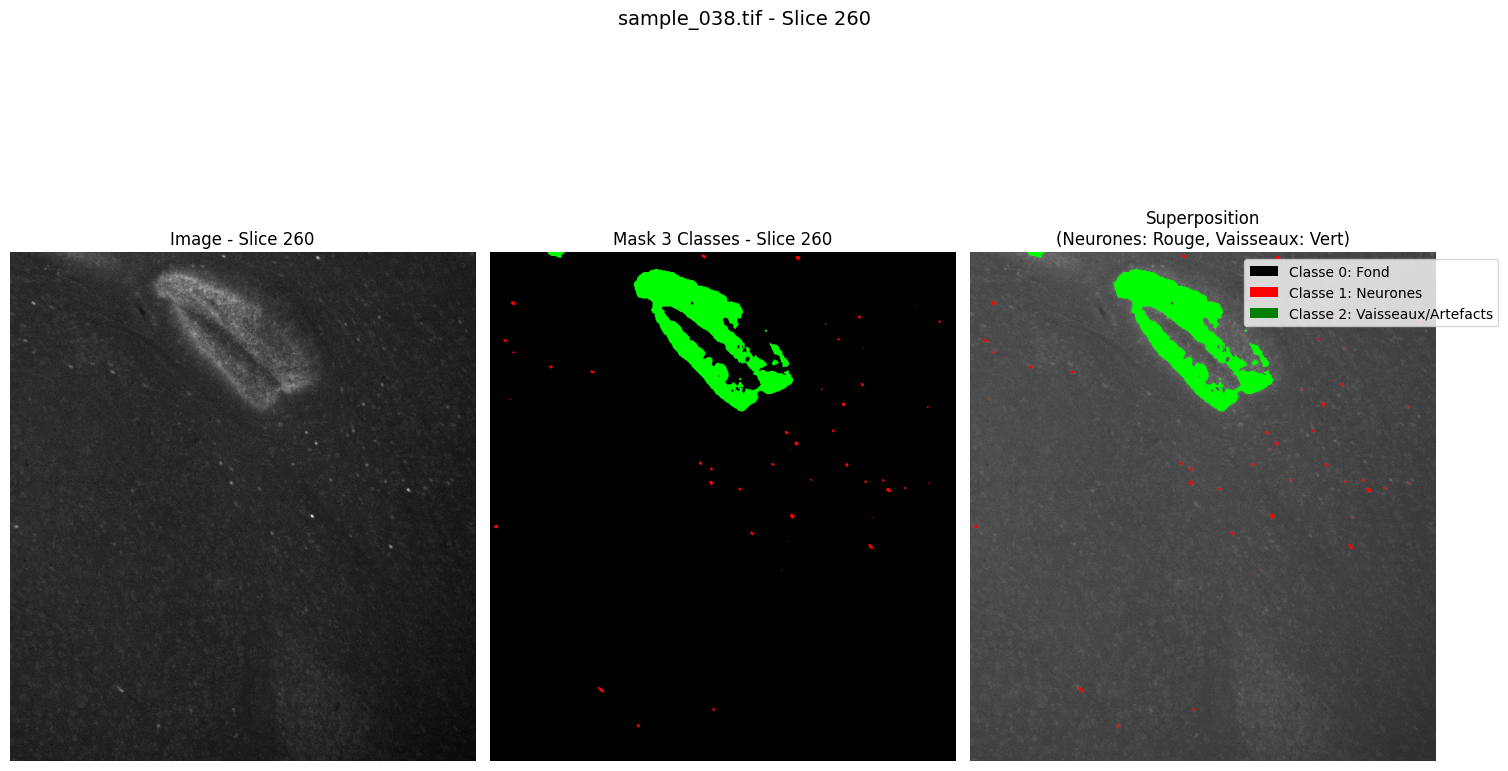

Statistiques de l'échantillon - Slice 260:
  Voxels fond (0): 355118
  Voxels neurones (1): 477
  Voxels vaisseaux (2): 12125

Visualisation de plusieurs slices de sample_038.tif
------------------------------------------------------------


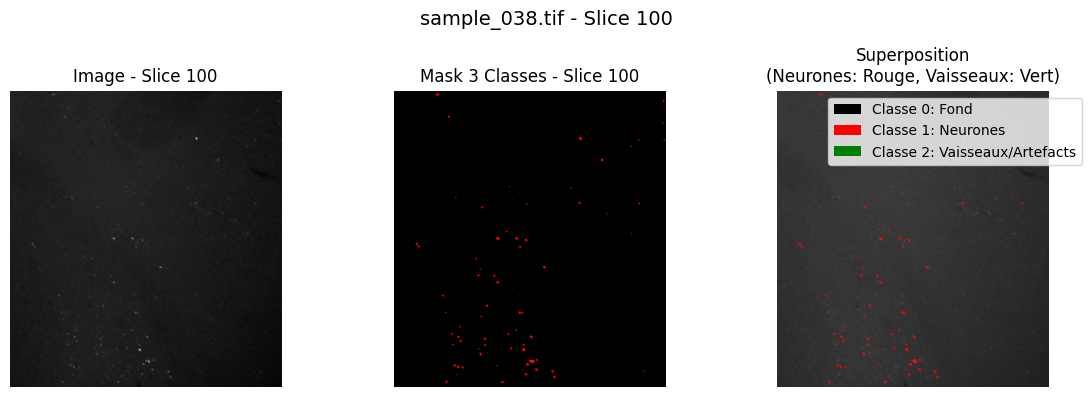

Statistiques de l'échantillon - Slice 100:
  Voxels fond (0): 366585
  Voxels neurones (1): 1129
  Voxels vaisseaux (2): 6


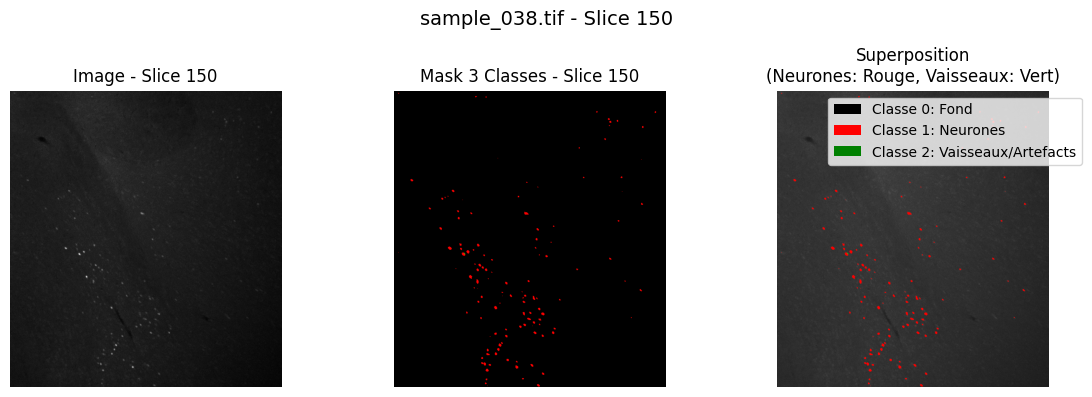

Statistiques de l'échantillon - Slice 150:
  Voxels fond (0): 365884
  Voxels neurones (1): 1831
  Voxels vaisseaux (2): 5


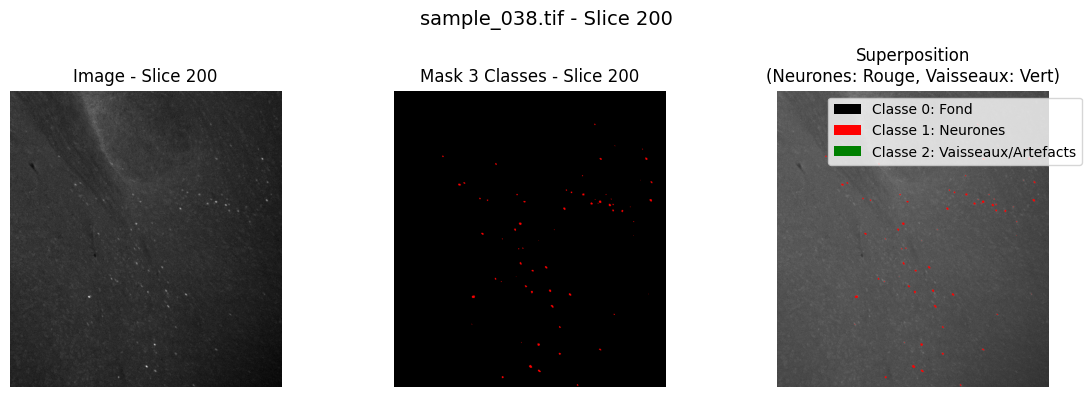

Statistiques de l'échantillon - Slice 200:
  Voxels fond (0): 367003
  Voxels neurones (1): 717
  Voxels vaisseaux (2): 0


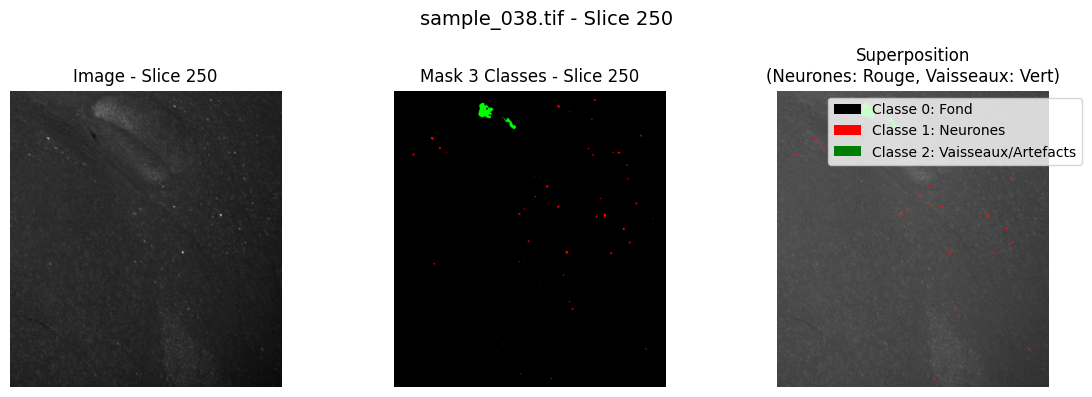

Statistiques de l'échantillon - Slice 250:
  Voxels fond (0): 366432
  Voxels neurones (1): 436
  Voxels vaisseaux (2): 852


In [9]:
if image_path.exists() and mask_path.exists():
    slice_index = 260
    
    print(f"\nVisualisation de sample_038.tif - Slice {slice_index}")
    print("-" * 60)
    
    visualize_image_and_mask_3class(
        image_array, 
        mask_array, 
        slice_index,
        title=f"{image_name} - Slice {slice_index}"
    )

if image_path.exists() and mask_path.exists():
    print("\nVisualisation de plusieurs slices de sample_038.tif")
    print("-" * 60)
    
    slices_to_show = [100, 150, 200, 250, 300, 350]
    
    for slice_idx in slices_to_show:
        if slice_idx < image_array.shape[0]:
            visualize_image_and_mask_3class(
                image_array, 
                mask_array, 
                slice_idx,
                title=f"{image_name} - Slice {slice_idx}",
                figsize=(12, 4)
            )


Visualisation d'images aléatoires
------------------------------------------------------------

Image: sample_010.tif
Image shape: (191, 242, 252)
Mask shape: (191, 242, 252)
Mask unique values: [0 1]


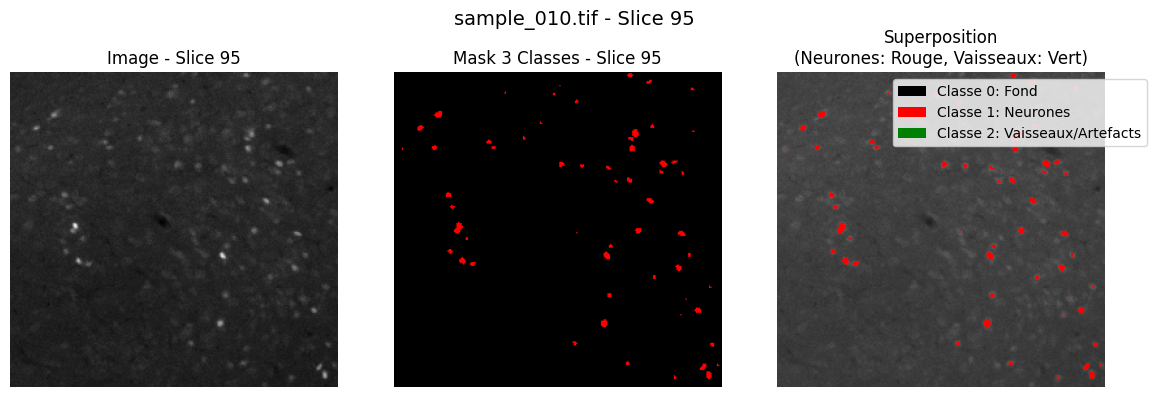

Statistiques de l'échantillon - Slice 95:
  Voxels fond (0): 60383
  Voxels neurones (1): 601
  Voxels vaisseaux (2): 0

Image: sample_005.tif
Image shape: (248, 341, 546)
Mask shape: (248, 341, 546)
Mask unique values: [0 1]


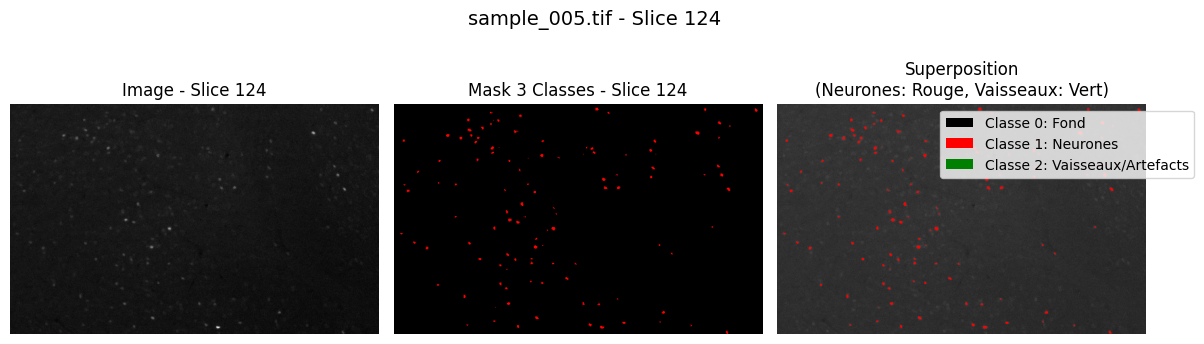

Statistiques de l'échantillon - Slice 124:
  Voxels fond (0): 185116
  Voxels neurones (1): 1070
  Voxels vaisseaux (2): 0

Image: sample_073.tif
Image shape: (201, 391, 418)
Mask shape: (201, 391, 418)
Mask unique values: [0 1 2]


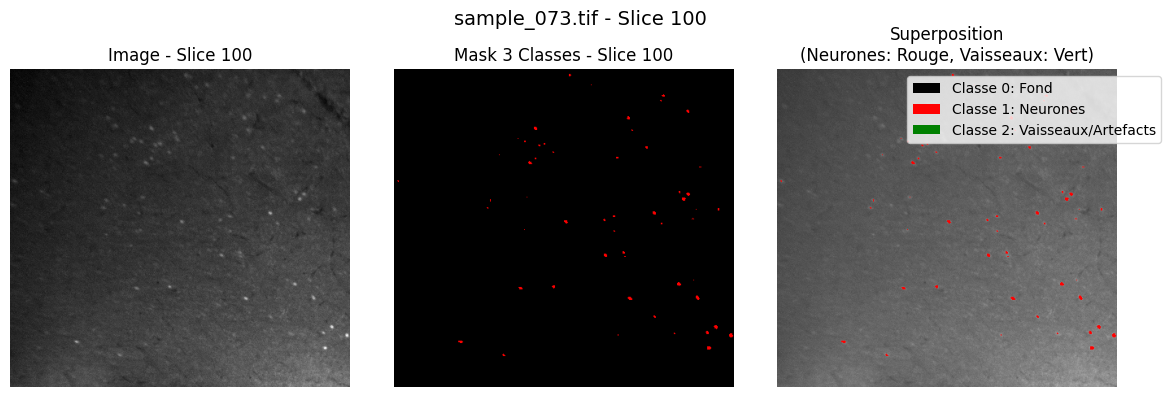

Statistiques de l'échantillon - Slice 100:
  Voxels fond (0): 163024
  Voxels neurones (1): 414
  Voxels vaisseaux (2): 0

Image: sample_045.tif
Image shape: (236, 431, 392)
Mask shape: (236, 431, 392)
Mask unique values: [0 1 2]


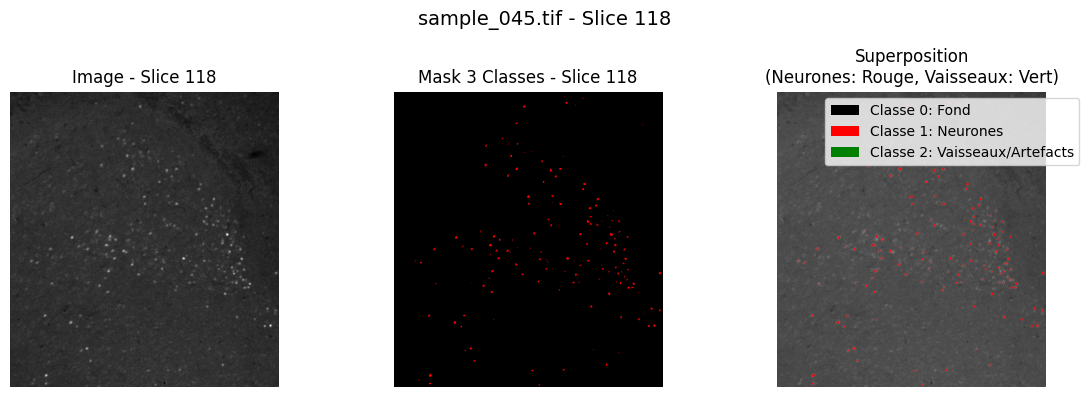

Statistiques de l'échantillon - Slice 118:
  Voxels fond (0): 168202
  Voxels neurones (1): 750
  Voxels vaisseaux (2): 0


In [10]:
print("\nVisualisation d'images aléatoires")
print("-" * 60)

import random

# Sélectionner quelques images aléatoires
num_samples = 4
selected_files = random.sample(image_files, min(num_samples, len(image_files)))

for img_file in selected_files:
    img_name = img_file.name
    mask_file = masks_brutes / img_name
    
    if mask_file.exists():
        print(f"\n{'='*60}")
        print(f"Image: {img_name}")
        print(f"{'='*60}")
        
        # Charger
        img_sitk = read_tif_image(str(img_file))
        msk_sitk = read_tif_image(str(mask_file))
        
        img_arr = convert_image_to_array(img_sitk)
        msk_arr = convert_image_to_array(msk_sitk)
        
        # Vérifier les dimensions
        print(f"Image shape: {img_arr.shape}")
        print(f"Mask shape: {msk_arr.shape}")
        print(f"Mask unique values: {np.unique(msk_arr)}")
        
        # Prendre le milieu
        middle_slice = img_arr.shape[0] // 2
        
        visualize_image_and_mask_3class(
            img_arr, 
            msk_arr, 
            middle_slice,
            title=f"{img_name} - Slice {middle_slice}",
            figsize=(12, 4)
        )

In [11]:
print("\n" + "=" * 60)
print("STATISTIQUES GLOBALES SUR LES DONNÉES BRUTES")
print("=" * 60)

all_shapes = []
all_classes_present = []

for i, img_file in enumerate(image_files[:20]):  # Limiter à 20 pour le test
    img_name = img_file.name
    mask_file = masks_brutes / img_name
    
    if mask_file.exists():
        try:
            msk_sitk = read_tif_image(str(mask_file))
            msk_arr = convert_image_to_array(msk_sitk)
            
            all_shapes.append(msk_arr.shape)
            unique_vals = np.unique(msk_arr)
            all_classes_present.append({
                "name": img_name,
                "shape": msk_arr.shape,
                "classes": unique_vals.tolist(),
                "has_class_0": 0 in unique_vals,
                "has_class_1": 1 in unique_vals,
                "has_class_2": 2 in unique_vals
            })
        except Exception as e:
            print(f"Erreur avec {img_name}: {e}")

# Afficher les statistiques
if all_classes_present:
    print(f"\nNombre d'échantillons analysés: {len(all_classes_present)}")
    
    has_class_1 = sum(1 for d in all_classes_present if d["has_class_1"])
    has_class_2 = sum(1 for d in all_classes_present if d["has_class_2"])
    has_all_3 = sum(1 for d in all_classes_present if d["has_class_0"] and d["has_class_1"] and d["has_class_2"])
    
    print(f"Images contenant des neurones (classe 1): {has_class_1}")
    print(f"Images contenant des vaisseaux (classe 2): {has_class_2}")
    print(f"Images contenant les 3 classes: {has_all_3}")
    
    # Dimensions
    if all_shapes:
        z_sizes = [s[0] for s in all_shapes]
        y_sizes = [s[1] for s in all_shapes]
        x_sizes = [s[2] for s in all_shapes]
        
        print(f"\nDimensions (Z, Y, X):")
        print(f"  Z: min={min(z_sizes)}, max={max(z_sizes)}, mean={np.mean(z_sizes):.1f}")
        print(f"  Y: min={min(y_sizes)}, max={max(y_sizes)}, mean={np.mean(y_sizes):.1f}")
        print(f"  X: min={min(x_sizes)}, max={max(x_sizes)}, mean={np.mean(x_sizes):.1f}")


STATISTIQUES GLOBALES SUR LES DONNÉES BRUTES

Nombre d'échantillons analysés: 20
Images contenant des neurones (classe 1): 20
Images contenant des vaisseaux (classe 2): 4
Images contenant les 3 classes: 4

Dimensions (Z, Y, X):
  Z: min=65, max=285, mean=150.8
  Y: min=196, max=687, mean=331.1
  X: min=182, max=589, mean=325.9



AFFICHAGE DÉTAILLÉ - sample_038.tif (Classes 0, 1, 2)


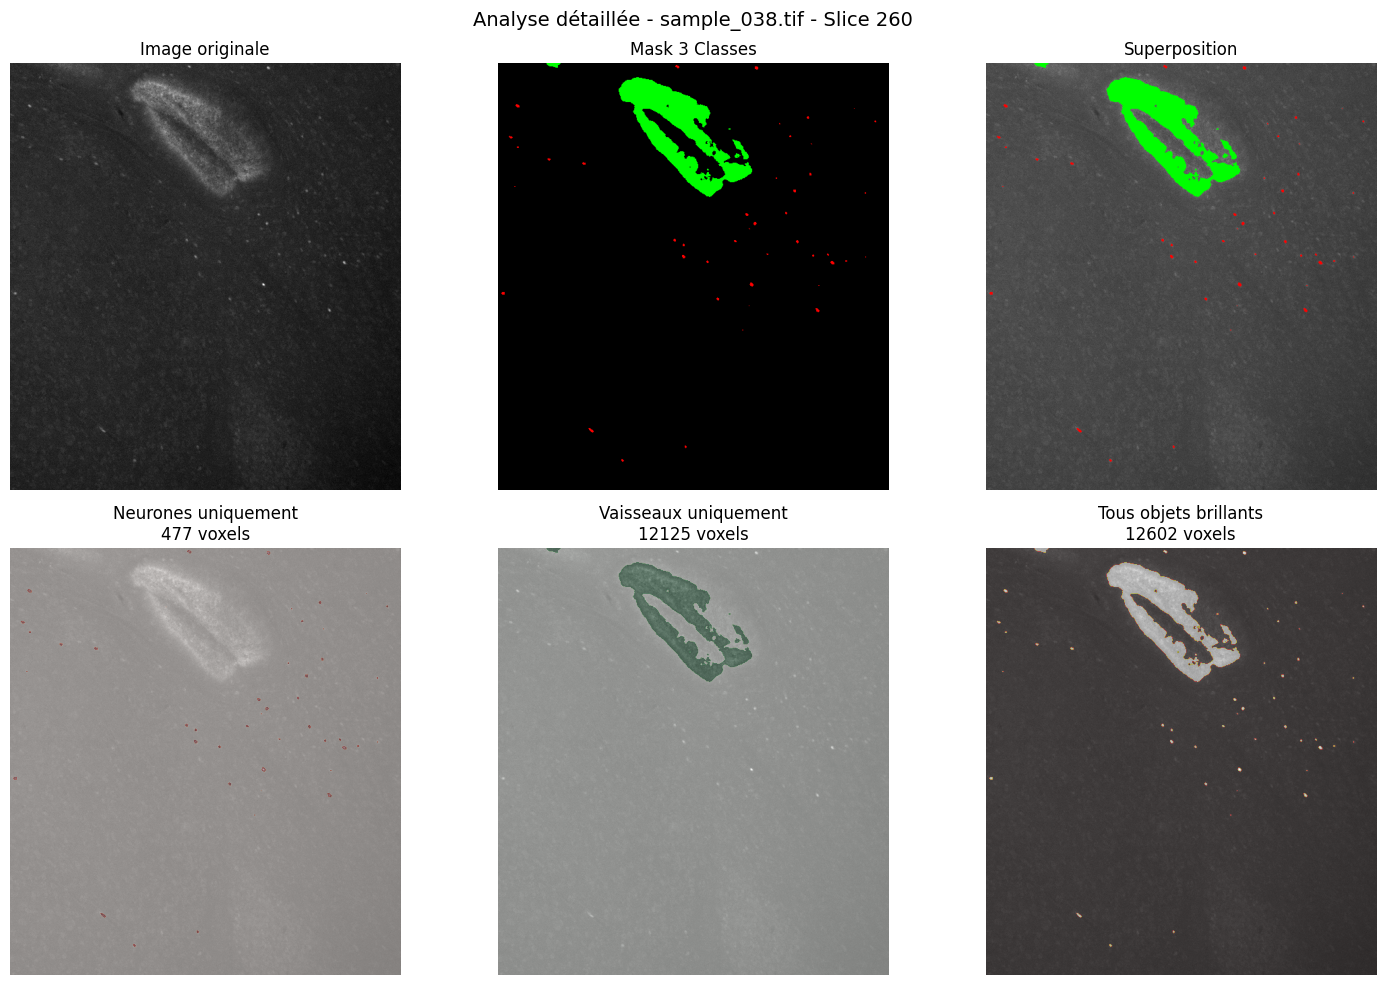

In [12]:
if image_path.exists() and mask_path.exists():
    print("\n" + "=" * 60)
    print("AFFICHAGE DÉTAILLÉ - sample_038.tif (Classes 0, 1, 2)")
    print("=" * 60)
    
    slice_index = 260
    
    img_slice = image_array[slice_index, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    mask_slice = mask_array[slice_index, :, :]
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Image seule
    axes[0, 0].imshow(img_slice, cmap='gray')
    axes[0, 0].set_title("Image originale")
    axes[0, 0].axis('off')
    
    # Mask 3 classes
    rgb_mask = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    rgb_mask[mask_slice == 0] = [0, 0, 0]
    rgb_mask[mask_slice == 1] = [1, 0, 0]
    rgb_mask[mask_slice == 2] = [0, 1, 0]
    axes[0, 1].imshow(rgb_mask)
    axes[0, 1].set_title("Mask 3 Classes")
    axes[0, 1].axis('off')
    
    # Superposition
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[mask_slice == 1, 0] = 1
    overlay[mask_slice == 1, 1] = 0
    overlay[mask_slice == 1, 2] = 0
    overlay[mask_slice == 2, 0] = 0
    overlay[mask_slice == 2, 1] = 1
    overlay[mask_slice == 2, 2] = 0
    axes[0, 2].imshow(overlay)
    axes[0, 2].set_title("Superposition")
    axes[0, 2].axis('off')
    
    # Seulement classe 1 (Neurones)
    mask_neurons = np.zeros_like(mask_slice, dtype=np.float32)
    mask_neurons[mask_slice == 1] = 1
    axes[1, 0].imshow(mask_neurons, cmap='Reds', alpha=0.7)
    axes[1, 0].imshow(img_slice, cmap='gray', alpha=0.5)
    axes[1, 0].set_title(f"Neurones uniquement\n{ (mask_slice == 1).sum()} voxels")
    axes[1, 0].axis('off')
    
    # Seulement classe 2 (Vaisseaux)
    mask_vessels = np.zeros_like(mask_slice, dtype=np.float32)
    mask_vessels[mask_slice == 2] = 1
    axes[1, 1].imshow(mask_vessels, cmap='Greens', alpha=0.7)
    axes[1, 1].imshow(img_slice, cmap='gray', alpha=0.5)
    axes[1, 1].set_title(f"Vaisseaux uniquement\n{ (mask_slice == 2).sum()} voxels")
    axes[1, 1].axis('off')
    
    # Classes 1 et 2 ensemble
    mask_both = np.zeros_like(mask_slice, dtype=np.float32)
    mask_both[(mask_slice == 1) | (mask_slice == 2)] = 1
    axes[1, 2].imshow(mask_both, cmap='hot', alpha=0.7)
    axes[1, 2].imshow(img_slice, cmap='gray', alpha=0.5)
    axes[1, 2].set_title(f"Tous objets brillants\n{(mask_slice == 1).sum() + (mask_slice == 2).sum()} voxels")
    axes[1, 2].axis('off')
    
    plt.suptitle("Analyse détaillée - sample_038.tif - Slice 260", fontsize=14)
    plt.tight_layout()
    plt.show()